In [335]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn import model_selection
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import matplotlib.pyplot as plt


In [336]:
df = pd.read_csv("../../data/features/09_popularity_features.csv")


In [337]:
df["log_revenue"].isna().sum()

np.int64(38032)

In [339]:
#removing any identifiers, or anything that will interrupt the model like string datatypes.
columns_to_drop = [
    "id",
    "log_revenue",
    "revenue_reported",
    "target_log_popularity",
    "genres",
    "production_companies",
    "production_countries",
    "spoken_languages",
    "director",
    "status",
    "title",
    "original_title",
    "overview",
    "top_cast",
    "keywords",
    "original_language"
]

x = df.drop(columns = columns_to_drop)
y = df['log_revenue'] 

In [340]:
print(x.select_dtypes(include=["object","string"]).columns) # checking to see if all the string values are gone which they are.


Index([], dtype='str')


In [342]:
x = x.fillna(0)
y= y.fillna(0)
print(x.isna().sum().sum()) 


0


## Making the splits for the model 80/10/10


In [343]:
#80% trainining with 20% remaining for validation and test
x_train,x_temp,y_train,y_temp = train_test_split(x,y,test_size=0.20,random_state=67)

#splitting the temp 20% into:
#10% validation and 10% test
x_val,x_test,y_val,y_test =train_test_split(x_temp,y_temp,test_size=.50,random_state=67)

In [344]:

#prints the number of rows, and columns makes sense since our dataset is split into 80/10/10 and makes up about 45k rows
#and we dropped ton of columns too that will interfere with the model
print("Training:", x_train.shape,y_train.shape)
print("Validation:", x_val.shape,y_val.shape)
print("Testing:",x_test.shape,y_test.shape)


Training: (36344, 18) (36344,)
Validation: (4543, 18) (4543,)
Testing: (4543, 18) (4543,)


In [345]:
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=67
)

model.fit(x_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## Configurations for the model

In [346]:
model_configuration = [
    {"n_estimators": 100, "max_depth": 2, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 2, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 2, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 3, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 4, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 4, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 5, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 5, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 6, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 6, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 6, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 7, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 7, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 7, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 7, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 7, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 8, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 8, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 8, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 8, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 8, "learning_rate": 0.05},


]

results = []
trained_models = {}

for model_number, config in enumerate(model_configuration,start =1):

    model = XGBRegressor(
        n_estimators= config["n_estimators"],
        max_depth = config["max_depth"],
        learning_rate = config["learning_rate"],
        objective = "reg:squarederror",
        random_state=67
    )

    #Train only using training data
    model.fit(x_train,y_train)

    #Predict using validation data
    y_val_pred = model.predict(x_val)

    mae = mean_absolute_error(y_val,y_val_pred)
    rmse = np.sqrt(mean_squared_error(y_val,y_val_pred))
    r2 = r2_score(y_val,y_val_pred)

    results.append({
        "model": model_number,
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "learning_rate": config["learning_rate"],
        "MAE" : mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[model_number] = model

results_df = pd.DataFrame(results)

results_df

    

,model,n_estimators,max_depth,learning_rate,MAE,RMSE,R2
0,1,100,2,0.01,3.100820,4.553951,0.450383
1,2,200,2,0.02,2.256688,4.038774,0.567702
2,3,300,2,0.03,2.151743,3.971649,0.581953
3,4,400,2,0.04,2.158802,3.950214,0.586453
4,5,500,2,0.05,2.169224,3.940533,0.588477
5,6,100,3,0.01,3.030469,4.458978,0.473068
6,7,200,3,0.02,2.167549,3.962705,0.583833
7,8,300,3,0.03,2.104295,3.917256,0.593325
8,9,400,3,0.04,2.105191,3.899784,0.596944
9,10,500,3,0.05,2.108756,3.893638,0.598214


In [347]:

#sorts from lowest to highest value of RMSE
# low mae, low rmse, and high r2 is considered the best model
results_df.sort_values(by="RMSE")

best_model_num = results_df.loc[results_df["RMSE"].idxmin(),"model"]

best_model = trained_models[best_model_num]

print("Best Model:", best_model_num) #prints model 5.

# best model configs
# n_estimators = 300, max_depth = 5, learning_rate =0.03

Best Model: 18


## Evaluting the selected(best) model with the test set

In [348]:
#Make predictions using only the testing set
y_test_pred = best_model.predict(x_test)

#calculating the metrics for mae,rmse,r2 with the test set.
test_mae = mean_absolute_error(y_test,y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test,y_test_pred))
test_r2 = r2_score(y_test,y_test_pred)

#dispalying metrics
print("Test MAE:", test_mae)
print("Test RMSE:", test_rmse)
print("Test R2:", test_r2)

Test MAE: 2.0860064464242134
Test RMSE: 3.9947916193925153
Test R2: 0.5509102288626246


## Visualization
- Compares the validation error for each of the tested configurations
- MAE and RMSE are error measurements and the lower values mean better perforamnce

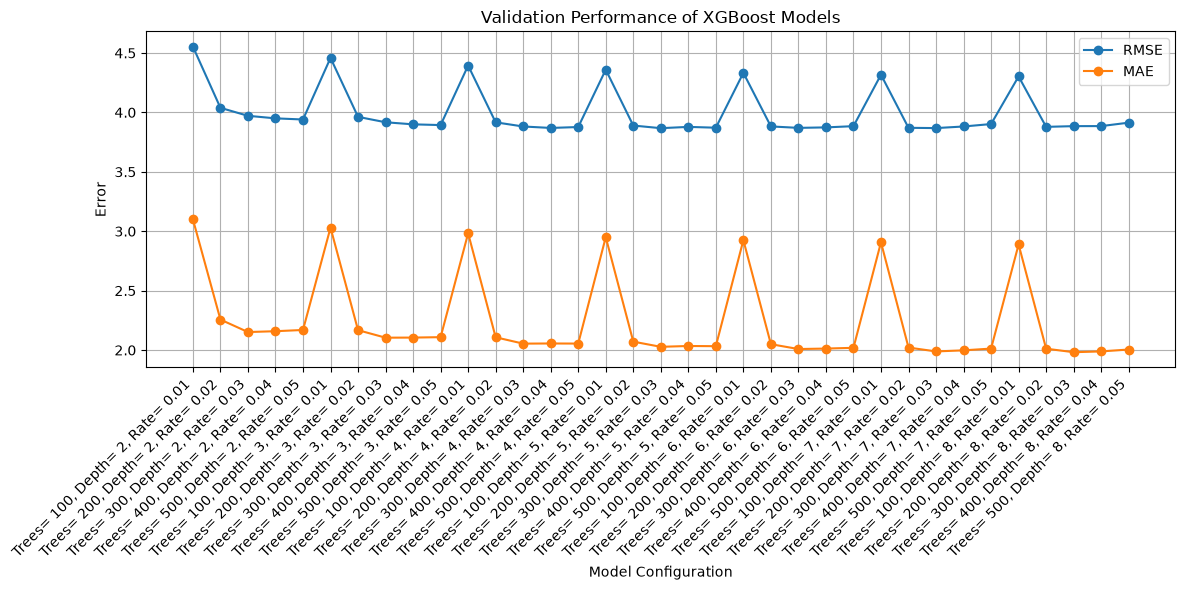

In [349]:
results_df["configuration"] = ("Trees= " + results_df["n_estimators"].astype(str) 
                               + ", Depth= " + results_df["max_depth"].astype(str)
                               + ", Rate= " + results_df["learning_rate"].astype(str))

plt.figure(figsize=(12,6))

plt.plot(results_df["configuration"],results_df["RMSE"],marker="o",label="RMSE")

plt.plot(results_df["configuration"],results_df["MAE"],marker="o",label="MAE")

plt.xlabel("Model Configuration")
plt.ylabel("Error")
plt.title("Validation Performance of XGBoost Models")
plt.xticks(rotation=45,ha="right")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Validation MAE and RMSE Graph
- MAE and RMSE measure predicition error
- Lower values mean the model's predicition is closer to the actual revenue
- Lowest RMSE would be selected as the best model which was 
`n_estimator = 300`, `max_depth = 5` , `learning_rate = 0.03`

## Validaiton R2 Graph
- Highest R2 values indiciate best performance 
- THe graph compares the highest R2 scores in different configurations 

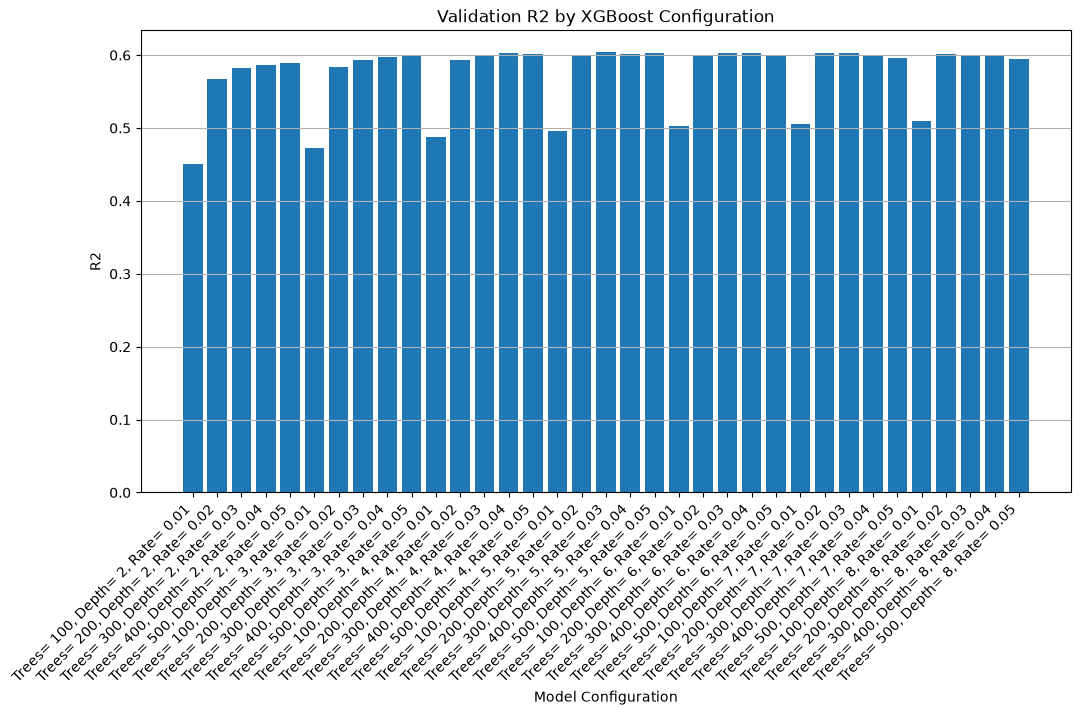

In [350]:
plt.figure(figsize=(12,6))

plt.bar(results_df["configuration"],results_df["R2"])

plt.xlabel("Model Configuration")
plt.ylabel("R2")
plt.title("Validation R2 by XGBoost Configuration")
plt.xticks(rotation=45,ha="right")
plt.grid(axis='y')
plt.show()

## Predicted vs. actual revenue plot for the selected model on the test set.


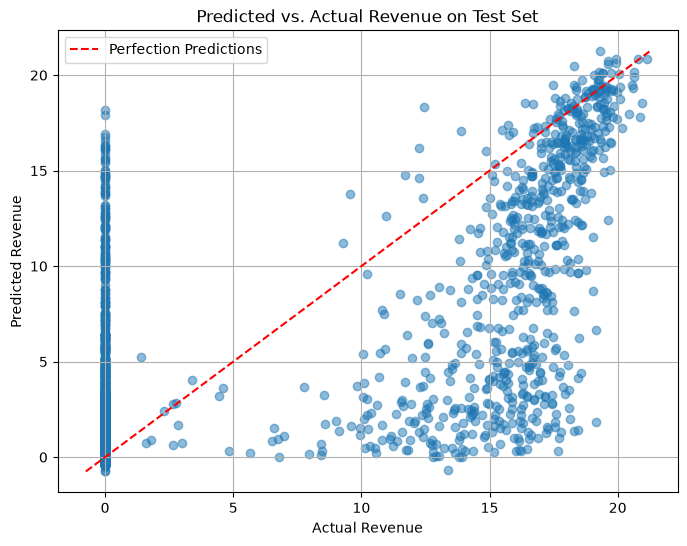

In [351]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,y_test_pred,alpha=0.5)

minimum = min(y_test.min(),y_test_pred.min())
maximum = max(y_test.max(),y_test_pred.max())

plt.plot([minimum,maximum],[minimum,maximum],color="red",linestyle="--",label="Perfection Predictions")

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Predicted vs. Actual Revenue on Test Set")
plt.legend()
plt.grid(True)
plt.show()


## 

## 

In [352]:
# Select one movie while keeping it as a 2D DataFrame
movie_sample = x_test.iloc[[0]]

# Predict its log revenue
predicted_log_revenue = best_model.predict(movie_sample)[0]

print("Predicted log revenue:", predicted_log_revenue)

Predicted log revenue: 0.08295529


## Optional Evaluation Visualizations

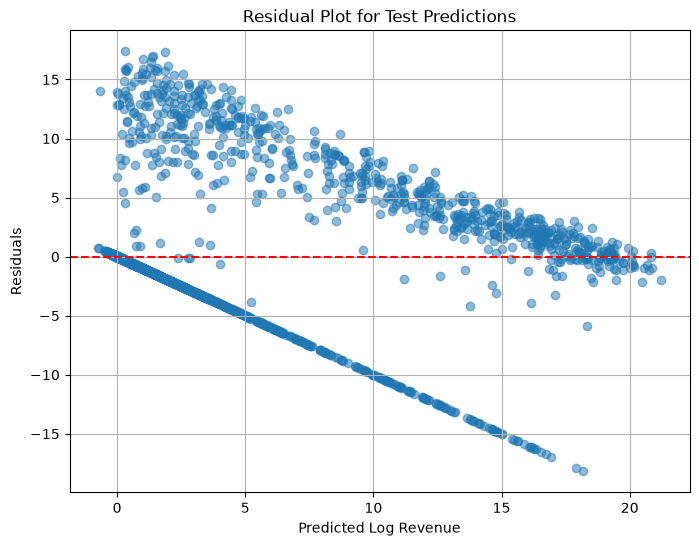

In [353]:
# actual value - predicted value that what residual is.
residuals = y_test - y_test_pred

plt.figure(figsize=(8,6))

plt.scatter(y_test_pred,residuals,alpha=0.5)
plt.axhline(y=0,color='red',linestyle="--")

plt.xlabel("Predicted Log Revenue")
plt.ylabel("Residuals")
plt.title("Residual Plot for Test Predictions")
plt.grid(True)
plt.show()

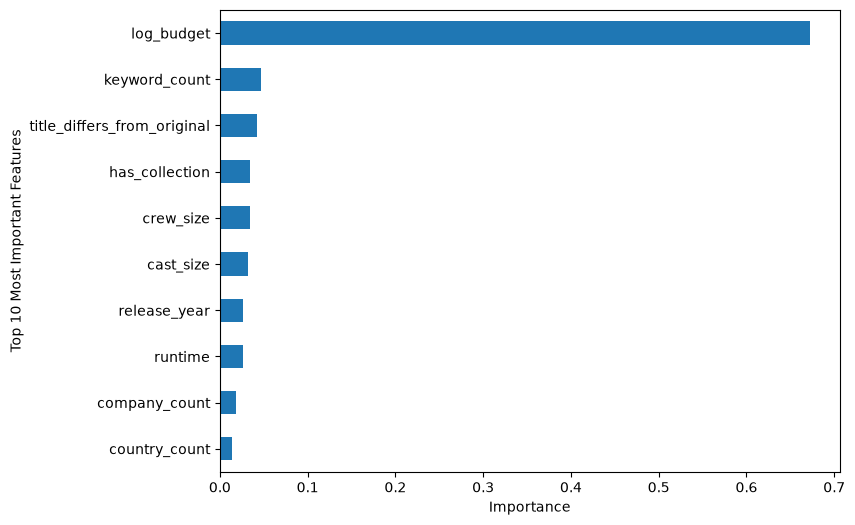

In [354]:
importance = pd.Series(best_model.feature_importances_,index=x_train.columns).sort_values(ascending=False).head(10)

importance.sort_values().plot(kind='barh',figsize=(8,6))

plt.xlabel("Importance")
plt.ylabel("Top 10 Most Important Features")
plt.show()

In [355]:
genre_df = pd.read_csv("../../data/features/10_genre_features.csv")
genre_df.columns

Index(['id', 'belongs_to_collection', 'production_companies',
       'production_countries', 'spoken_languages', 'director', 'top_cast',
       'cast_size', 'crew_size', 'keywords', 'title', 'original_title',
       'overview', 'original_language', 'status', 'has_collection',
       'company_count', 'country_count', 'spoken_languages_count',
       'has_director', 'keyword_count', 'title_word_count',
       'overview_word_count', 'title_differs_from_original', 'Drama', 'Crime',
       'Comedy', 'Action', 'Thriller', 'Adventure', 'Science Fiction',
       'Animation', 'Family', 'Romance', 'Mystery', 'Music', 'Horror',
       'Fantasy', 'Documentary', 'War', 'Western', 'History', 'Foreign',
       'TV Movie', 'release_year', 'release_month', 'release_decade',
       'log_budget', 'log_revenue', 'runtime', 'log_popularity'],
      dtype='str')

In [356]:
genre_columns = [
    'Drama',
    'Crime',
    'Comedy',
    'Action',
    'Thriller',
    'Adventure',
    'Science Fiction',
    'Animation',
    'Family',
    'Romance',
    'Mystery',
    'Music',
    'Horror',
    'Fantasy',
    'Documentary',
    'War',
    'Western',
    'History',
    'Foreign',
    'TV Movie'
]

X_genres = genre_df[genre_columns]
Y_genres = genre_df['log_revenue'].fillna(0)

print(X_genres.isna().sum())



Drama              0
Crime              0
Comedy             0
Action             0
Thriller           0
Adventure          0
Science Fiction    0
Animation          0
Family             0
Romance            0
Mystery            0
Music              0
Horror             0
Fantasy            0
Documentary        0
War                0
Western            0
History            0
Foreign            0
TV Movie           0
dtype: int64


In [357]:


#using 80% on training the model
x_train_genres,x_temp_genres,y_train_genres,y_temp_genres = train_test_split(X_genres,Y_genres,test_size=0.20,random_state=67)

# using remaining 20 percent 10% validation an 10% test
x_val_genres,x_test_genres,y_val_genres,y_test_genres = train_test_split(x_temp_genres,y_temp_genres,test_size=0.50,random_state=67)


In [358]:
#Shape of sets
print(x_train_genres.shape)
print(x_val_genres.shape)
print(x_test_genres.shape)

(36346, 20)
(4543, 20)
(4544, 20)


In [359]:
#Training new model

genre_model = XGBRegressor(n_estimators=200,max_depth=3,learning_rate=0.10,objective="reg:squarederror",random_state=67)

genre_model.fit(x_train_genres,y_train_genres)



,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [360]:
#Predict validation values
y_val_genres_pred = genre_model.predict(x_val_genres)

#Calculate validation metrics
genre_mae = mean_absolute_error(y_val_genres,y_val_genres_pred)
genre_rmse = np.sqrt(mean_squared_error(y_val_genres,y_val_genres_pred))
genre_r2 = r2_score(y_val_genres,y_val_genres_pred)

print("Genre Model Validation MAE:", genre_mae)
print("Genre Model Validation RMSE:", genre_rmse)
print("Genre Model Validation R2:", genre_r2)

Genre Model Validation MAE: 3.9432956256138456
Genre Model Validation RMSE: 5.643605094227133
Genre Model Validation R2: 0.08278901618570544


In [364]:
model_configuration_genre = [
    {"n_estimators": 100, "max_depth": 2, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 2, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 2, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 2, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 3, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 4, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 4, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 5, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 5, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 5, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 6, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 6, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 6, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 7, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 7, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 7, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 7, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 7, "learning_rate": 0.05},
    {"n_estimators": 100, "max_depth": 8, "learning_rate": 0.01},
    {"n_estimators": 200, "max_depth": 8, "learning_rate": 0.02},
    {"n_estimators": 300, "max_depth": 8, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 8, "learning_rate": 0.04},
    {"n_estimators": 500, "max_depth": 8, "learning_rate": 0.05},


]

results_genre = []
trained_models_genre = {}

for model_number_genre, config in enumerate(model_configuration_genre,start =1):

    genre_model = XGBRegressor(
        n_estimators= config["n_estimators"],
        max_depth = config["max_depth"],
        learning_rate = config["learning_rate"],
        objective = "reg:squarederror",
        random_state=67
    )

    #Train only using training data
    genre_model.fit(x_train_genres,y_train_genres)

    #Predict using validation data
    y_val_genres_pred = genre_model.predict(x_val_genres)

    mae = mean_absolute_error(y_val_genres,y_val_genres_pred)
    rmse = np.sqrt(mean_squared_error(y_val_genres,y_val_genres_pred))
    r2 = r2_score(y_val_genres,y_val_genres_pred)

    results_genre.append({
        "model": model_number_genre,
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "learning_rate": config["learning_rate"],
        "MAE" : mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models_genre[model_number_genre] = genre_model

results_genres_df = pd.DataFrame(results_genre)

results_genres_df



,model,n_estimators,max_depth,learning_rate,MAE,RMSE,R2
0,1,100,2,0.01,4.182137,5.798903,0.031616
1,2,200,2,0.02,4.080619,5.714850,0.059485
2,3,300,2,0.03,4.018764,5.683545,0.069761
3,4,400,2,0.04,3.989464,5.671063,0.073842
4,5,500,2,0.05,3.978414,5.665020,0.075815
5,6,100,3,0.01,4.150675,5.762046,0.043887
6,7,200,3,0.02,4.029357,5.676611,0.072029
7,8,300,3,0.03,3.969456,5.651745,0.080141
8,9,400,3,0.04,3.949840,5.645634,0.082130
9,10,500,3,0.05,3.938119,5.642550,0.083132


In [366]:

#sorts from lowest to highest value of RMSE
# low mae, low rmse, and high r2 is considered the best model
results_genres_df.sort_values(by="RMSE")

best_model_num_genre = results_genres_df.loc[results_genres_df["RMSE"].idxmin(),"model"]

best_model_genre = trained_models_genre[best_model_num_genre]

print("Best Model:", best_model_num_genre) 

# best model configs
# n_estimators = 300, max_depth = 4, learning_rate =0.03

Best Model: 13


In [368]:
genre_importance = pd.DataFrame({"genre": x_train_genres.columns, 
                                 "importance": best_model_genre.feature_importances_}).sort_values(by="importance",ascending=False)

genre_importance

,genre,importance
5,Adventure,0.175400
4,Thriller,0.098980
18,Foreign,0.075574
9,Romance,0.071378
3,Action,0.070463
19,TV Movie,0.060630
1,Crime,0.058170
13,Fantasy,0.053647
2,Comedy,0.053449
0,Drama,0.045203


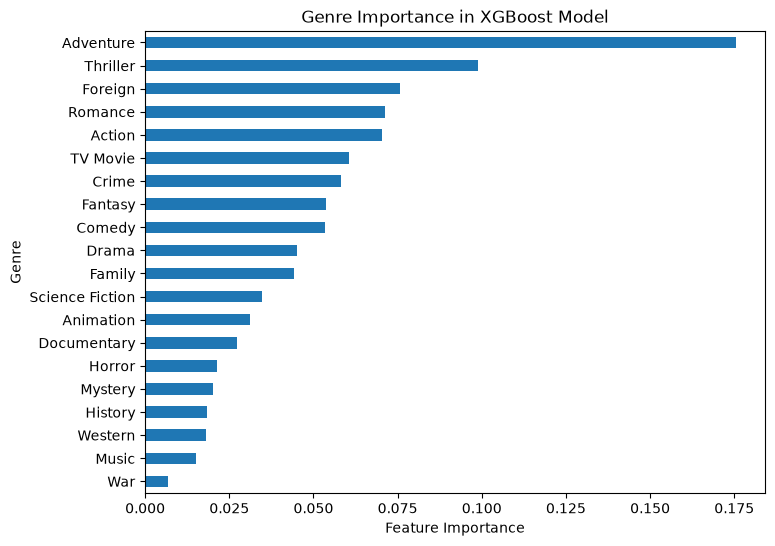

In [371]:
genre_importance.sort_values("importance").plot(
    kind='barh',
    x='genre',
    y='importance',
    figsize=(8,6),
    legend=False
)

plt.xlabel("Feature Importance")
plt.ylabel("Genre")
plt.title("Genre Importance in XGBoost Model")
plt.show()

In [372]:
genre_revenue = []

for genre in genre_columns:
    movies_with_genre = X_genres[genre] == 1

    genre_revenue.append({
        "genre": genre.replace("genre_", "").replace("_", " ").title(),
        "average_log_revenue": Y_genres[movies_with_genre].mean(),
        "movie_count": movies_with_genre.sum()
    })

genre_revenue_df = pd.DataFrame(genre_revenue)

genre_revenue_df = genre_revenue_df.sort_values(
    by="average_log_revenue",
    ascending=False
)

genre_revenue_df

,genre,average_log_revenue,movie_count
5,Adventure,5.603646,3490
13,Fantasy,4.709270,2309
3,Action,4.437603,6592
8,Family,4.262503,2767
6,Science Fiction,4.138509,3044
1,Crime,4.102107,4304
4,Thriller,4.001966,7619
10,Mystery,3.648586,2464
7,Animation,3.435218,1931
17,History,3.409069,1398


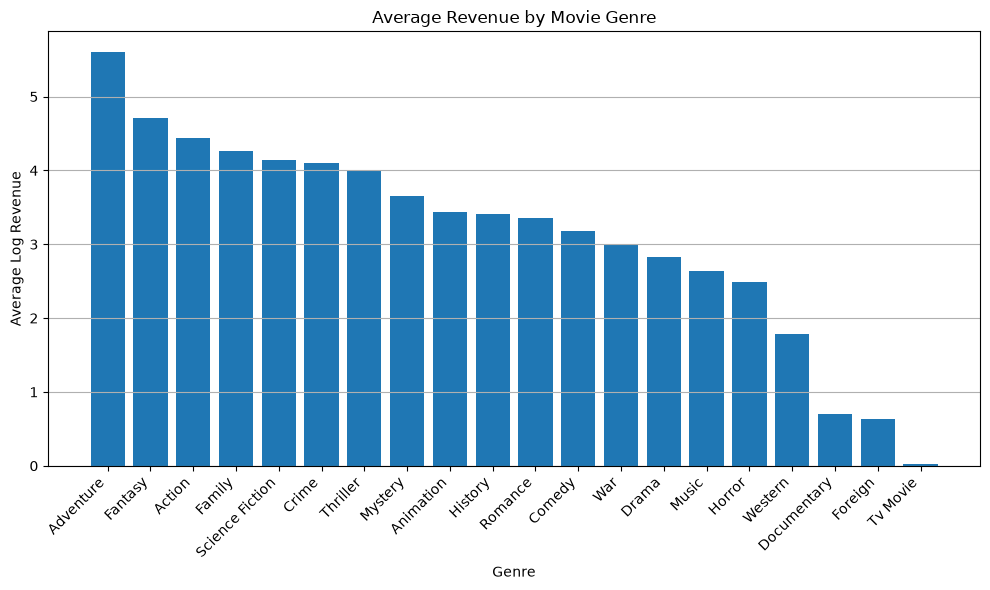

In [ ]:

plt.figure(figsize=(10, 6))

plt.bar(
    genre_revenue_df["genre"],
    genre_revenue_df["average_log_revenue"]
)

plt.xlabel("Genre")
plt.ylabel("Average Log Revenue")
plt.title("Average Revenue by Movie Genre")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()